In [2]:
import os
import h5py
import math
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import seaborn as sns
import pandas as pd
import pickle
from sklearn.utils import resample
import matplotlib as mpl


In [3]:
import os
import h5py

directory_path = ""
Genome_path = ""
p1 = h5py.File(f"{directory_path}Translatome_rep3.h5", 'r')
p2 = h5py.File(f"{directory_path}TOM_interactome_rep3.h5", 'r')

def calculate_total_counts(group, file_handle, force=False):

    output_file = f"{directory_path}{group}_count_reads"

    # Load cached value unless force=True
    if os.path.exists(output_file) and not force:
        with open(output_file, 'r') as f:
            total_counts = int(float(f.readline().strip()))
            print(f"Loaded total reads for {group}: {total_counts}")
            return total_counts
    df = pd.read_csv(f"{Genome_path}all_genes_location_without_chx.csv")
    total_counts = 0

    for gene in df['gene']:
        if gene in file_handle:     # use current file only
            total_counts += file_handle[gene][1].sum()

    with open(output_file, 'w') as f:
        f.write(str(total_counts))

    print(f"Calculated and saved total reads for {group}: {total_counts}")
    return total_counts


# force recalculation
p1_Total_Reads = calculate_total_counts('p1', p1, force=True)
p2_Total_Reads = calculate_total_counts('p2', p2, force=True)


Calculated and saved total reads for p1: 7401435.0
Calculated and saved total reads for p2: 2385434.0


In [4]:
import numpy as np

# median total counts per gene
p1_counts = [
    p1[gene][1].sum()
    for gene in p1.keys()
]

p2_counts = [
    p2[gene][1].sum()
    for gene in p2.keys()
]

print(
    "Translatome CHX median:",
    np.median(p1_counts)
)

print(
    "TOM interactome CHX median:",
    np.median(p2_counts)
)

Translatome CHX median: 172.0
TOM interactome CHX median: 42.0


In [5]:
genes_p1 = set(p1.keys())
genes_p2 = set(p2.keys())

common_genes = genes_p1.intersection(genes_p2)
unique_p1 = genes_p1 - genes_p2
unique_p2 = genes_p2 - genes_p1

print(f"Genes in p1: {len(genes_p1)}")
print(f"Genes in p2: {len(genes_p2)}")
print(f"Common genes: {len(common_genes)}")
print(f"Unique to p1: {len(unique_p1)}")
print(f"Unique to p2: {len(unique_p2)}")

Genes in p1: 14222
Genes in p2: 13753
Common genes: 13099
Unique to p1: 1123
Unique to p2: 654


In [6]:
def nt_to_codon(group, gene):
    p = p1 if group == group1 else p2
    codon_dict = defaultdict(int)

    for index, nt_position in enumerate(p[gene][0].tolist()):
        codon_idx = math.ceil(nt_position / 3)
        codon_dict[codon_idx] += p[gene][1][index]

    return codon_dict

# Function to process gene trace
def gene_trace(group, gene):
    Reads, p = (p1_Total_Reads, p1) if group == group1 else (p2_Total_Reads, p2)
    codon_length = int(p[gene].attrs['cds_length']) // 3
    Dict_c = nt_to_codon(group, gene)
    
    window, flank = 15, 7  # Adjusted flank calculation for clarity

    # Normalize codon reads
    Dict_c = {k: 0.05 + (Dict_c.get(k, 0) / Reads * 1e6) for k in range(1, codon_length + 1)}

    # Apply smoothing
    Dict_s = {}
    for i in range(1, codon_length + 1):
        start, end = max(1, i - flank), min(codon_length, i + flank)
        Dict_s[i] = sum(Dict_c[j] for j in range(start, end + 1)) / (end - start + 1)

    return sorted(Dict_s.items())

# Function to compute gene enrichment
def gene_enrichment(gene):
    List1, List2 = gene_trace('p1', gene), gene_trace('p2', gene)
    x1, y1 = zip(*List1)
    x2, y2 = zip(*List2)

    y3 = [(y2[i] / y1[i]) if y1[i] != 0 and y2[i] != 0 else np.nan for i in range(len(y1))]
    y4 = [0] * len(x1)

    return x1, y1, y2, y3, y4


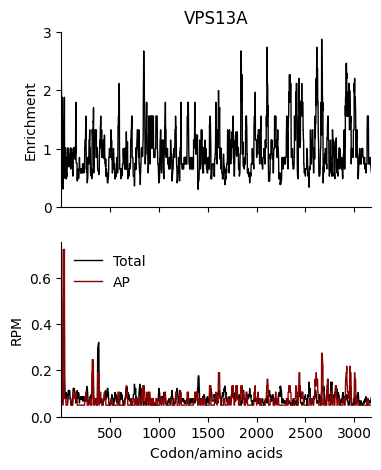

In [8]:
def nt_to_codon(group, gene):
    p = p1 if group == 'p1' else p2
    codon_dict = defaultdict(int)

    for index, nt_position in enumerate(p[gene][0].tolist()):
        codon_idx = math.ceil(nt_position / 3)
        codon_dict[codon_idx] += p[gene][1][index]

    return codon_dict


def gene_trace(group, gene):
    Reads, p = (
        (p1_Total_Reads, p1)
        if group == 'p1'
        else (p2_Total_Reads, p2)
    )

    codon_length = int(p[gene].attrs['cds_length']) // 3
    Dict_c = nt_to_codon(group, gene)

    window, flank = 15, 7

    # Normalize codon reads
    Dict_c = {
        k: 0.05 + (Dict_c.get(k, 0) / Reads * 1e6)
        for k in range(1, codon_length + 1)
    }

    # Apply smoothing
    Dict_s = {}
    for i in range(1, codon_length + 1):
        start = max(1, i - flank)
        end = min(codon_length, i + flank)

        Dict_s[i] = (
            sum(Dict_c[j] for j in range(start, end + 1))
            / (end - start + 1)
        )

    return sorted(Dict_s.items())
plot_gene_enrichment('VPS13A')



Requested genes:
['AARS1', 'ABL1', 'ACIN1', 'ACTR1B', 'ADCY9', 'ADGRG6', 'AGFG1', 'AHSA1', 'AKAP13', 'AKAP9', 'ALDOA', 'AMBRA1', 'AMOT', 'ANAPC11', 'ANKS1A', 'ANO9', 'ANXA11', 'AP1G1', 'AP5Z1', 'APBB1', 'ARAP1', 'ARFGAP2', 'ARFIP2', 'ARHGAP35', 'ARHGAP6', 'ARHGEF18', 'ARPC1A', 'ASAP1', 'ASH1L', 'ASH2L', 'ATG4D', 'ATP2A2', 'ATP2B1', 'ATP2C1', 'ATP6V0A1', 'ATP6V1F', 'ATXN7L3B', 'BAHCC1', 'BAIAP2L1', 'BANF1', 'BAZ1B', 'BBX', 'BCL9', 'BCOR', 'BCR', 'BICRA', 'BPTF', 'BRCA1', 'BRD9', 'BRF1', 'BRPF1', 'BRPF3', 'BSG', 'BTF3', 'C1orf112', 'C1orf122', 'C20orf27', 'C7orf50', 'CABIN1', 'CACHD1', 'CACNG8', 'CAD', 'CALD1', 'CAMSAP1', 'CANT1', 'CASC3', 'CAST', 'CCDC137', 'CCDC85B', 'CCNG1', 'CCNI', 'CCNK', 'CCR10', 'CDC37', 'CDC42BPA', 'CDC42BPB', 'CDC73', 'CDCA4', 'CDCA8', 'CDIPT', 'CDK12', 'CDK5', 'CDK5RAP2', 'CELSR3', 'CEP164', 'CEP85', 'CFDP1', 'CHAF1A', 'CHD3', 'CHD9', 'CHFR', 'CHPF2', 'CIC', 'CIT', 'CLCN3', 'CLTC', 'CLUH', 'CMIP', 'CMTR1', 'CNNM4', 'CNOT10', 'CNOT6', 'CNTROB', 'COPB2', 'COPG2'

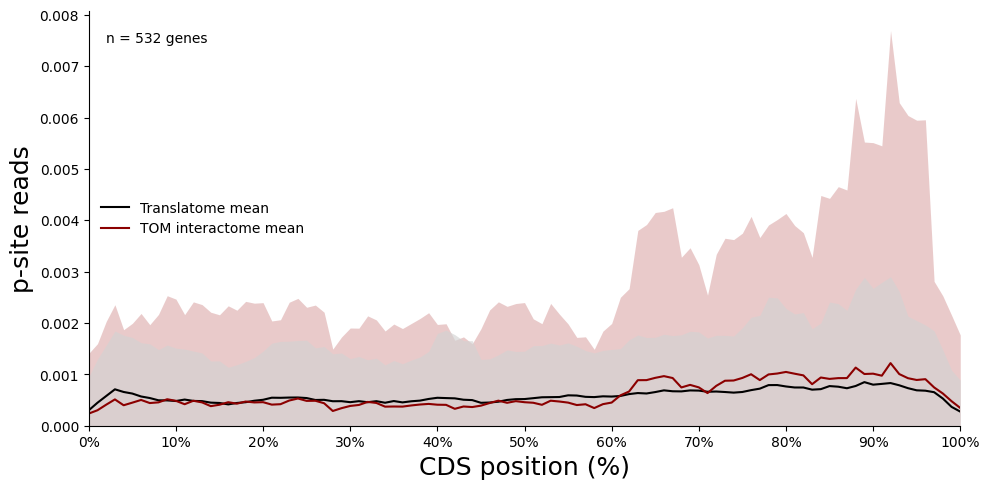

In [4]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


# ============================================================
# USER SETTINGS
# ============================================================

TRANS_FILE = "Translatome_CHX_rep1.h5"
INTERACTOME_FILE = "TOM_interactome_CHX_rep1.h5"

GENES = [
    "AARS1",
    "ABL1",
    "ACIN1",
    "ACTR1B",
    "ADCY9",
    "ADGRG6",
    "AGFG1",
    "AHSA1",
    "AKAP13",
    "AKAP9",
    "ALDOA",
    "AMBRA1",
    "AMOT",
    "ANAPC11",
    "ANKS1A",
    "ANO9",
    "ANXA11",
    "AP1G1",
    "AP5Z1",
    "APBB1",
    "ARAP1",
    "ARFGAP2",
    "ARFIP2",
    "ARHGAP35",
    "ARHGAP6",
    "ARHGEF18",
    "ARPC1A",
    "ASAP1",
    "ASH1L",
    "ASH2L",
    "ATG4D",
    "ATP2A2",
    "ATP2B1",
    "ATP2C1",
    "ATP6V0A1",
    "ATP6V1F",
    "ATXN7L3B",
    "BAHCC1",
    "BAIAP2L1",
    "BANF1",
    "BAZ1B",
    "BBX",
    "BCL9",
    "BCOR",
    "BCR",
    "BICRA",
    "BPTF",
    "BRCA1",
    "BRD9",
    "BRF1",
    "BRPF1",
    "BRPF3",
    "BSG",
    "BTF3",
    "C1orf112",
    "C1orf122",
    "C20orf27",
    "C7orf50",
    "CABIN1",
    "CACHD1",
    "CACNG8",
    "CAD",
    "CALD1",
    "CAMSAP1",
    "CANT1",
    "CASC3",
    "CAST",
    "CCDC137",
    "CCDC85B",
    "CCNG1",
    "CCNI",
    "CCNK",
    "CCR10",
    "CDC37",
    "CDC42BPA",
    "CDC42BPB",
    "CDC73",
    "CDCA4",
    "CDCA8",
    "CDIPT",
    "CDK12",
    "CDK5",
    "CDK5RAP2",
    "CELSR3",
    "CEP164",
    "CEP85",
    "CFDP1",
    "CHAF1A",
    "CHD3",
    "CHD9",
    "CHFR",
    "CHPF2",
    "CIC",
    "CIT",
    "CLCN3",
    "CLTC",
    "CLUH",
    "CMIP",
    "CMTR1",
    "CNNM4",
    "CNOT10",
    "CNOT6",
    "CNTROB",
    "COPB2",
    "COPG2",
    "COPS8",
    "CORO1C",
    "CPNE3",
    "CPSF2",
    "CRYBG3",
    "CSNK1G2",
    "CTCF",
    "CTNNB1",
    "CTPS1",
    "CTU2",
    "DAB2IP",
    "DAZAP1",
    "DBN1",
    "DBNL",
    "DCAF6",
    "DCAF7",
    "DCTN1",
    "DDX5",
    "DDX56",
    "DGCR2",
    "DGKQ",
    "DHCR24",
    "DNMT1",
    "DOT1L",
    "DPH1",
    "DST",
    "DUS3L",
    "DYNC1H1",
    "DYNC2H1",
    "DYNLT1",
    "DYRK1A",
    "DZIP3",
    "E2F7",
    "EAF1",
    "EDC3",
    "EEF1AKNMT",
    "EI24",
    "EIF2B2",
    "ENAH",
    "ENKD1",
    "ENPP1",
    "ENY2",
    "EP400",
    "ERBIN",
    "ETS2",
    "EVL",
    "EVX2",
    "EWSR1",
    "EXPH5",
    "EZH1",
    "FAM120A",
    "FANCG",
    "FAT3",
    "FBRSL1",
    "FBXO21",
    "FBXO46",
    "FGFR3",
    "FLT4",
    "FMR1",
    "FOXD1",
    "FOXG1",
    "FRAS1",
    "FREM2",
    "FRY",
    "FTSJ1",
    "FUBP1",
    "FUBP3",
    "FUZ",
    "FXR2",
    "FYN",
    "FZD8",
    "GAPVD1",
    "GATA2",
    "GATAD2A",
    "GBA2",
    "GBF1",
    "GJC1",
    "GMPPA",
    "GNAS",
    "GNB1",
    "GNL3L",
    "GORASP2",
    "GPI",
    "GPS1",
    "GRB10",
    "GRB2",
    "GRIN2D",
    "GSE1",
    "H2AZ2",
    "H3C13",
    "H4C1",
    "HDAC7",
    "HIPK1",
    "HOXA10",
    "HOXD11",
    "HSPG2",
    "IGF2BP1",
    "IGF2BP2",
    "INPP4A",
    "INTS14",
    "IPO9",
    "IQSEC1",
    "ISY1",
    "ITPRID2",
    "ITSN2",
    "JARID2",
    "JUND",
    "KATNB1",
    "KCNC4",
    "KDM2A",
    "KDM2B",
    "KHSRP",
    "KIAA1549",
    "KIDINS220",
    "KIF20A",
    "KIF5B",
    "KMT2C",
    "KNTC1",
    "KRI1",
    "L3MBTL2",
    "LAMTOR5",
    "LARP4B",
    "LBHD1",
    "LIMA1",
    "LRBA",
    "LRFN1",
    "LRP10",
    "LSM7",
    "MACF1",
    "MAP1B",
    "MAP3K10",
    "MAP3K4",
    "MAPK8IP2",
    "MARK2",
    "MASTL",
    "MBD6",
    "MBNL1",
    "MCMBP",
    "MECP2",
    "MED12",
    "MED23",
    "METTL7A",
    "MKI67",
    "MLEC",
    "MNX1",
    "MOB1A",
    "MORC2",
    "MSI1",
    "MTA2",
    "MTCL1",
    "MTHFD1",
    "MTMR1",
    "MTPN",
    "MYH10",
    "MYO1C",
    "MYO6",
    "MYSM1",
    "NAA38",
    "NACA",
    "NASP",
    "NCAPH",
    "NCKAP5L",
    "NDRG3",
    "NEMP1",
    "NF1",
    "NFE2L1",
    "NOP14",
    "NPEPPS",
    "NRBP1",
    "NSD2",
    "NSDHL",
    "NTMT1",
    "NTN1",
    "NUMA1",
    "NVL",
    "OCRL",
    "ORC3",
    "PA2G4",
    "PABPC1L",
    "PABPC4",
    "PABPN1",
    "PACC1",
    "PACS1",
    "PAFAH1B3",
    "PALD1",
    "PALLD",
    "PAPOLA",
    "PARP6",
    "PATL1",
    "PCF11",
    "PCIF1",
    "PCNT",
    "PCNX2",
    "PDCD6IP",
    "PDIA6",
    "PDXK",
    "PEAK1",
    "PGP",
    "PHACTR4",
    "PHC2",
    "PHF2",
    "PHKA1",
    "PHLDB1",
    "PHPT1",
    "PI4KB",
    "PIAS4",
    "PIK3R4",
    "PIN1",
    "PKD1",
    "PKMYT1",
    "PKN1",
    "PLEC",
    "PLEKHH3",
    "PNP",
    "POLA2",
    "POLR3H",
    "POMT1",
    "POP7",
    "PPP1CB",
    "PPP1R35",
    "PPP2CA",
    "PPP6R1",
    "PRDM2",
    "PRPSAP2",
    "PRR12",
    "PRR14L",
    "PSEN2",
    "PSMC5",
    "PSMD13",
    "PSME3",
    "PSMF1",
    "PTPN13",
    "PTTG1",
    "PXN",
    "QPRT",
    "R3HDM2",
    "R3HDM4",
    "RAB1A",
    "RAB7A",
    "RAD21",
    "RAPGEF2",
    "RAPH1",
    "RARS1",
    "RAVER2",
    "RBM12B",
    "RBM19",
    "RBM22",
    "RBM28",
    "RBM6",
    "RDH11",
    "RERE",
    "RINT1",
    "RIOK3",
    "RNF216",
    "RNF220",
    "RNPS1",
    "RO60",
    "ROBO1",
    "RPA2",
    "RPL15",
    "RPL18A",
    "RPL26",
    "RPL29",
    "RPL4",
    "RPP25L",
    "RPS11",
    "RPS2",
    "RPS21",
    "RPS5",
    "RPS6KB2",
    "RPSA",
    "RRBP1",
    "RTCB",
    "RUSC1",
    "SAFB",
    "SAFB2",
    "SAMD4B",
    "SART1",
    "SBNO1",
    "SCML1",
    "SEC16A",
    "SEC31A",
    "SEMA6A",
    "SERINC3",
    "SETD2",
    "SETX",
    "SEZ6L2",
    "SF1",
    "SF3A3",
    "SF3B4",
    "SH3GL1",
    "SH3GLB2",
    "SHISA5",
    "SHKBP1",
    "SHPK",
    "SHPRH",
    "SIK2",
    "SIL1",
    "SIPA1L2",
    "SIRT6",
    "SLAIN1",
    "SLC3A2",
    "SLC6A6",
    "SLC6A9",
    "SLC7A5",
    "SLC7A6",
    "SLK",
    "SMARCC1",
    "SMARCD3",
    "SMG1",
    "SMG5",
    "SMG6",
    "SNRPA",
    "SNRPB",
    "SOAT1",
    "SOX12",
    "SPECC1",
    "SPECC1L",
    "SPEN",
    "SPTAN1",
    "SPTLC1",
    "SRRM2",
    "SRRT",
    "SRSF7",
    "SS18",
    "STEAP3",
    "STIP1",
    "STK11",
    "STRN3",
    "SUGP2",
    "SUPT16H",
    "SUPT6H",
    "SYNE1",
    "SYNE2",
    "TAB2",
    "TAF2",
    "TATDN2",
    "TET1",
    "TFG",
    "THADA",
    "THAP4",
    "THOC2",
    "TIMELESS",
    "TLE1",
    "TLE3",
    "TM9SF3",
    "TMCO1",
    "TMED8",
    "TMEM104",
    "TMEM131",
    "TMEM30A",
    "TNKS1BP1",
    "TNRC6B",
    "TNRC6C",
    "TOM1",
    "TOP2A",
    "TOPBP1",
    "TPR",
    "TRAFD1",
    "TRAIP",
    "TRIO",
    "TRIOBP",
    "TRIP11",
    "TSC22D3",
    "TSN",
    "TTLL4",
    "TUT4",
    "UBA52",
    "UBAC1",
    "UBAP2",
    "UBE2L3",
    "UBE2M",
    "UBE4B",
    "UBQLN4",
    "UBR2",
    "UHRF1BP1",
    "UNC13B",
    "UNKL",
    "URB2",
    "USF1",
    "USP24",
    "USP42",
    "USP7",
    "UVSSA",
    "UXT",
    "VANGL1",
    "VASP",
    "VCAN",
    "VPS33A",
    "VPS35L",
    "VPS72",
    "WAC",
    "WARS1",
    "WASF1",
    "WASF2",
    "WBP11",
    "WDFY3",
    "WDR1",
    "WDR33",
    "WDR5",
    "WDR6",
    "WDR62",
    "WIZ",
    "WNK1",
    "WTAP",
    "XPC",
    "XPO6",
    "XPR1",
    "XRN2",
    "YEATS2",
    "YIPF3",
    "YWHAG",
    "ZBED4",
    "ZBTB40",
    "ZBTB7A",
    "ZC3H15",
    "ZC3HC1",
    "ZIC5",
    "ZMYM4",
    "ZMYND8",
    "ZNF106",
    "ZNF276",
    "ZRANB2",
    "ZNF687",
    "ZNF704",
    "ZNF746",
    "ZNF768",
]
# Number of points used to represent each CDS
N_POINTS = 101

# Smoothing in percentage-of-CDS bins
SMOOTHING = 5

OUTPUT_FILE = "gene_individual_and_mean_CDS_percentage.png"


percent_axis = np.linspace(
    0,
    100,
    N_POINTS
)


# ============================================================
# FUNCTION: GET ONE GENE PROFILE
# ============================================================
def get_gene_profile(h5_file, gene):

    if gene not in h5_file:
        print(f"{gene}: not found")
        return None

    try:

        ds = h5_file[gene]

        # CDS length — KEEP THIS AS A SINGLE NUMBER
        cds_length = int(
            ds.attrs["cds_length"]
        )

        positions = ds[0].astype(int)
        reads = ds[1].astype(float)

        # ----------------------------------------------------
        # Create profile across CDS
        #
        # 0 = CDS START
        # cds_length = CDS END / STOP
        # ----------------------------------------------------

        profile = np.zeros(
            cds_length + 1,
            dtype=float
        )

        for pos, read in zip(
            positions,
            reads
        ):

            if 0 <= pos <= cds_length:

                profile[pos] += read

        # ----------------------------------------------------
        # Normalize each gene to itself
        # ----------------------------------------------------

        total_counts = profile.sum()

        if total_counts <= 0:

            print(f"{gene}: no reads")

            return None

        profile_normalized = (
            profile / total_counts
        )

        # ----------------------------------------------------
        # Convert CDS position to percentage
        #
        # 0%   = START
        # 100% = END / STOP
        # ----------------------------------------------------

        gene_percent = (
            np.arange(cds_length + 1)
            / cds_length
            * 100
        )

        # ----------------------------------------------------
        # Put every gene onto common 0–100% axis
        # ----------------------------------------------------

        profile_interpolated = np.interp(
            percent_axis,
            gene_percent,
            profile_normalized
        )

        return profile_interpolated

    except Exception as e:

        print(
            f"{gene}: skipped because {e}"
        )

        return None


# ============================================================
# FUNCTION: LOAD ALL GENES
# ============================================================

def load_profiles(
    filename,
    genes
):

    profiles = {}

    with h5py.File(
        filename,
        "r"
    ) as h5:

        for gene in genes:

            profile = get_gene_profile(
                h5,
                gene
            )

            if profile is not None:

                profiles[gene] = profile

    return profiles


# ============================================================
# LOAD TRANS LATOME
# ============================================================

trans_profiles = load_profiles(
    TRANS_FILE,
    GENES
)


# ============================================================
# LOAD INTERACTOME
# ============================================================

inter_profiles = load_profiles(
    INTERACTOME_FILE,
    GENES
)


# ============================================================
# FIND GENES PRESENT IN BOTH
# ============================================================

common_genes = [
    gene
    for gene in GENES
    if gene in trans_profiles
    and gene in inter_profiles
]


print("\nRequested genes:")
print(GENES)

print("\nGenes present in both datasets:")
print(common_genes)

print(
    f"\nNumber of genes analyzed: "
    f"{len(common_genes)}"
)


if len(common_genes) == 0:

    raise ValueError(
        "No genes were found in both datasets."
    )


# ============================================================
# CREATE MATRICES
# ============================================================

trans_matrix = np.vstack([
    trans_profiles[gene]
    for gene in common_genes
])

inter_matrix = np.vstack([
    inter_profiles[gene]
    for gene in common_genes
])


# ============================================================
# SMOOTHING FUNCTION
# ============================================================

def smooth_profile(
    profile,
    window
):

    if window <= 1:
        return profile

    kernel = np.ones(
        window
    ) / window

    return np.convolve(
        profile,
        kernel,
        mode="same"
    )


# ============================================================
# SMOOTH EACH INDIVIDUAL GENE
# ============================================================

trans_matrix_smoothed = np.array([
    smooth_profile(
        profile,
        SMOOTHING
    )
    for profile in trans_matrix
])

inter_matrix_smoothed = np.array([
    smooth_profile(
        profile,
        SMOOTHING
    )
    for profile in inter_matrix
])


# ============================================================
# CALCULATE MEAN
# ============================================================

trans_mean = np.mean(
    trans_matrix_smoothed,
    axis=0
)

inter_mean = np.mean(
    inter_matrix_smoothed,
    axis=0
)

# ============================================================
# SHADOW = STANDARD DEVIATION ACROSS GENES
# ============================================================

if len(common_genes) > 1:

    trans_sd = np.std(
        trans_matrix_smoothed,
        axis=0,
        ddof=1
    )

    inter_sd = np.std(
        inter_matrix_smoothed,
        axis=0,
        ddof=1
    )

else:

    trans_sd = np.zeros_like(trans_mean)
    inter_sd = np.zeros_like(inter_mean)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)


ax.fill_between(
    percent_axis,
    np.maximum(0, trans_mean - trans_sd),
    trans_mean + trans_sd,
    color="lightgray",
    alpha=0.65,
    linewidth=0,
    zorder=2
)

ax.fill_between(
    percent_axis,
    np.maximum(0, inter_mean - inter_sd),
    inter_mean + inter_sd,
    color="#D8A0A0",
    alpha=0.55,
    linewidth=0,
    zorder=1
)
ax.plot(
    percent_axis,
    trans_mean,
    color="black",
    linewidth=1.5,
    label="Translatome mean"
)


# ============================================================
# MEAN INTERACTOME
# ============================================================

ax.plot(
    percent_axis,
    inter_mean,
    color="darkred",
    linewidth=1.5,
    label="TOM interactome mean"
)





# ============================================================
# X AXIS
# ============================================================


# ============================================================
# X AXIS
# ============================================================

ax.set_xlim(
    0,
    100
)

ax.set_xticks(
    np.arange(0, 101, 10)
)

ax.set_xticklabels([
    f"{x}%"
    for x in np.arange(0, 101, 10)
])

ax.set_xlabel(
    "CDS position (%)",
    fontsize=18
)

ax.set_ylabel(
    "p-site reads",
    fontsize=18
)

ax.xaxis.set_major_locator(
    ticker.MultipleLocator(10)
)


# ============================================================
# Y AXIS
# ============================================================

ax.set_ylim(
    bottom=0
)


# ============================================================
# STYLE
# ============================================================

ax.spines["top"].set_visible(
    False
)

ax.spines["right"].set_visible(
    False
)

ax.legend(
    frameon=False,
    fontsize=10
)


# ============================================================
# GENE COUNT
# ============================================================

ax.text(
    0.02,
    0.95,
    f"n = {len(common_genes)} genes",
    transform=ax.transAxes,
    fontsize=10,
    va="top"
)


# ============================================================
# SAVE + SHOW
# ============================================================

plt.tight_layout()

plt.savefig(
    OUTPUT_FILE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


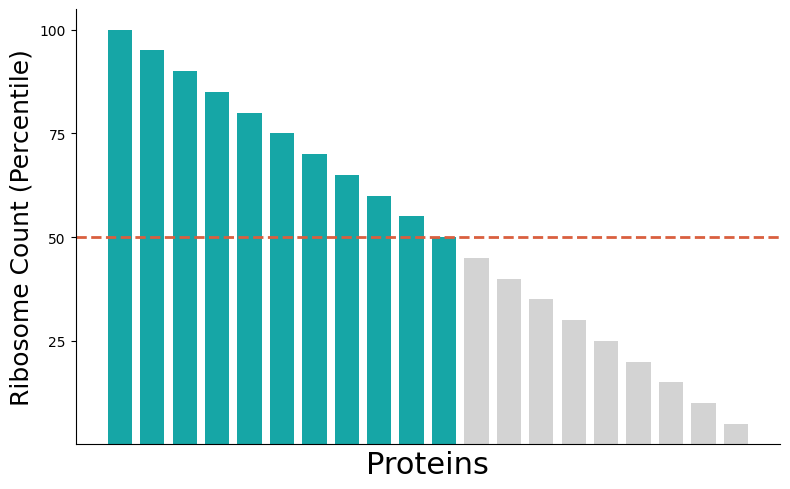

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# RIBOSOME COUNTS
# ============================================================

counts = np.array([
    95, 90, 78, 74, 70, 66, 62, 57, 52, 48,
    44, 40, 35, 30, 26, 22, 18, 14, 10, 5
])

# Sort highest → lowest
counts = np.sort(counts)[::-1]

# ============================================================
# CONVERT TO PERCENTILE
# ============================================================

n = len(counts)

percentile = (
    np.arange(n, 0, -1)
    / n
    * 100
)

# Make sure the highest protein is exactly 100
percentile[0] = 100

# ============================================================
# MEDIAN CUTOFF
# ============================================================

median_cutoff = 50

high_occupancy = percentile >= median_cutoff

x = np.arange(n)

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)

# ------------------------------------------------------------
# All proteins
# ------------------------------------------------------------

ax.bar(
    x,
    percentile,
    width=0.75,
    color="lightgray",
    edgecolor="none"
)

# ------------------------------------------------------------
# Proteins >= 50th percentile
# ------------------------------------------------------------

ax.bar(
    x[high_occupancy],
    percentile[high_occupancy],
    width=0.75,
    color="#16A6A6",
    edgecolor="none"
)

# ============================================================
# MEDIAN CUTOFF
# ============================================================

ax.axhline(
    50,
    color="#D95F3F",
    linestyle="--",
    linewidth=2
)

# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(
    "Proteins",
    fontsize=22
)

ax.set_ylabel(
    "Ribosome Count (Percentile)",
    fontsize=18
)

# ============================================================
# Y AXIS
# ============================================================

ax.set_ylim(
    0,
    105
)

ax.set_yticks([
    25,
    50,
    75,
    100
])

ax.set_yticklabels([
    "25",
    "50",
    "75",
    "100"
])

# ============================================================
# X AXIS
# ============================================================

ax.set_xticks([])

# ============================================================
# STYLE
# ============================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "rank_proteins_ribosome_percentile.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [130]:
def load_gene_localization(file_path):
    df = pd.read_csv(file_path)
    return df.set_index('gene')['localization'].to_dict()

gene_localization = load_gene_localization(f"{Genome_path}all_genes_location_without_chx.csv")

# Calculate RPKM
def calculate_rpkm(count, total_reads, length):
    if total_reads == 0 or length == 0:
        return np.nan
    return (count / total_reads / length) * 1e9

# Process gene data
def process_gene_data(gene):
    if gene not in p1 or gene not in p2:
        return None

    p1_count = sum(p1[gene][1])
    p2_count = sum(p2[gene][1])
    length = int(p1[gene].attrs['cds_length'])
    codon_length = length // 3

    p1_RPKM = calculate_rpkm(p1_count, p1_Total_Reads, length)
    p2_RPKM = calculate_rpkm(p2_count, p2_Total_Reads, length)

    ratio = p2_RPKM / p1_RPKM if p1_RPKM > 0 else np.nan
    log2_ratio = np.log2(ratio) if ratio > 0 else np.nan

    p1_norm = p1_count / codon_length if codon_length > 0 else np.nan
    p2_norm = p2_count / codon_length if codon_length > 0 else np.nan

    return {
        'localization': gene_localization.get(gene, 'Unknown'),
        'Length': codon_length,
        f'{group1}_count': p1_count,
        f'{group2}_count': p2_count,
        f'{group1}_RPKM': p1_RPKM,
        f'{group2}_RPKM': p2_RPKM,
        'ratio': ratio,
        'Log2_ratio': log2_ratio,
        f'{group1}_norm': p1_norm,
        f'{group2}_norm': p2_norm
    }

# Generate gene enrichment dataframe
def generate_gene_enrichment_dataframe():
    gene_loc = {gene: data for gene in gene_localization if (data := process_gene_data(gene))}
    gene_loc_df = pd.DataFrame.from_dict(gene_loc, orient='index')
    gene_loc_df.index.name = 'gene'
    gene_loc_df = gene_loc_df.sort_values(by='ratio', ascending=False)
    # gene_loc_df.to_csv(f"{directory_path}/without_chx/gene_enrichment_list_rep2.csv")
    return gene_loc_df

gene_loc_df = generate_gene_enrichment_dataframe()

# Apply threshold to filter genes
def filter_genes_by_threshold(df, threshold=42):
    filtered_df = df.loc[(df[f'{group1}_count'] >= threshold) & (df[f'{group2}_count'] >= threshold)]
    # filtered_df.to_csv(f"{directory_path}/without_chx/gene_enrichment_list_threshold_rep3_median.csv")
    return filtered_df

filtered_gene_loc_df = filter_genes_by_threshold(gene_loc_df)

# Merge and save results
# def merge_and_save(file_path, enrichment_file, output_file):
#     df1 = pd.read_csv(enrichment_file)
#     df2 = pd.read_csv(file_path)
#     merged_df = pd.merge(df1, df2, on = 'gene', how='inner')
#     merged_df.to_csv(output_file, index=False)

# merge_and_save(f"{Genome_path}human_mitochondrial_proteins_MTS.csv",
#                 f"{directory_path}gene_enrichment_list.csv",
#                 f"{directory_path}Mito_gene_enrichment_list.csv")

# merge_and_save(f"{Genome_path}APEX all annotation_uniprot.csv",
#                 f"{directory_path}gene_enrichment_list.csv",
#                 f"{directory_path}gene_enrichment_list_APEX.csv")


In [15]:
import os
import glob
import numpy as np
import pandas as pd
from functools import reduce

folder = f"{directory_path}/without_chx"


files = sorted(
    glob.glob(
        f"{folder}/gene_enrichment_list_threshold_rep*_median.csv"
    )
)

dfs = []

for i, file in enumerate(files):

    df = pd.read_csv(file)

    df = df[
        [
            'gene',
            'localization',
            'p1_RPKM',
            'p2_RPKM'
        ]
    ].copy()

    # rename replicate columns
    df = df.rename(columns={
        'p1_RPKM': f'p1_RPKM_rep{i+1}',
        'p2_RPKM': f'p2_RPKM_rep{i+1}'
    })

    dfs.append(df)

# keep only common genes
merged = reduce(
    lambda left, right:
        pd.merge(
            left,
            right.drop(columns='localization'),
            on='gene',
            how='inner'
        ),
    dfs
)

# average RPKM
p1_cols = [c for c in merged.columns if 'p1_RPKM' in c]
p2_cols = [c for c in merged.columns if 'p2_RPKM' in c]

merged['avg_p1_RPKM'] = merged[p1_cols].mean(axis=1)
merged['avg_p2_RPKM'] = merged[p2_cols].mean(axis=1)

# enrichment
merged['ratio'] = (
    merged['avg_p2_RPKM']
    /
    merged['avg_p1_RPKM']
)

merged['Log2_ratio'] = np.log2(
    merged['ratio']
)

# keep final columns only
final = merged[
    [
        'gene',
        'localization',
        'avg_p1_RPKM',
        'avg_p2_RPKM',
        'ratio',
        'Log2_ratio'
    ]
]

final.to_csv(
    f"{folder}/merged_avg_RPKM_median.csv",
    index=False
)

print("Genes present in all replicates:", len(final))
print(final.head())

TypeError: reduce() of empty sequence with no initial value

In [18]:
import os
import glob
import numpy as np
import pandas as pd
from functools import reduce

folder = f"with_chx"

files = sorted(
    glob.glob(
        f"{folder}/gene_enrichment_list_threshold_rep*_median.csv"
    )
)

print("Folder:", folder)
print("Number of files found:", len(files))

for f in files:
    print(os.path.basename(f))

if not files:
    raise FileNotFoundError(
        f"No files found matching:\n"
        f"{folder}/gene_enrichment_list_threshold_rep*_median.csv"
    )

dfs = []

for i, file in enumerate(files):

    df = pd.read_csv(file)

    df = df[
        [
            'gene',
            'localization',
            'p1_RPKM',
            'p2_RPKM'
        ]
    ].copy()

    df = df.rename(columns={
        'p1_RPKM': f'p1_RPKM_rep{i+1}',
        'p2_RPKM': f'p2_RPKM_rep{i+1}'
    })

    dfs.append(df)


# --------------------------------------------------
# Keep only genes common to all replicates
# --------------------------------------------------

merged = reduce(
    lambda left, right:
        pd.merge(
            left,
            right.drop(columns='localization'),
            on='gene',
            how='inner'
        ),
    dfs
)


# --------------------------------------------------
# Average RPKM
# --------------------------------------------------

p1_cols = [
    c for c in merged.columns
    if c.startswith('p1_RPKM_rep')
]

p2_cols = [
    c for c in merged.columns
    if c.startswith('p2_RPKM_rep')
]

merged['avg_p1_RPKM'] = merged[p1_cols].mean(axis=1)
merged['avg_p2_RPKM'] = merged[p2_cols].mean(axis=1)


# --------------------------------------------------
# Enrichment
# --------------------------------------------------

merged['ratio'] = (
    merged['avg_p2_RPKM'] /
    merged['avg_p1_RPKM']
)

merged['Log2_ratio'] = np.log2(merged['ratio'])


# --------------------------------------------------
# Final output
# --------------------------------------------------

final = merged[
    [
        'gene',
        'localization',
        'avg_p1_RPKM',
        'avg_p2_RPKM',
        'ratio',
        'Log2_ratio'
    ]
]

output_file = f"{folder}/merged_avg_RPKM_median.csv"

final.to_csv(
    output_file,
    index=False
)

print("Genes present in all replicates:", len(final))
print("Output:", output_file)
print(final.head())


Folder: with_chx
Number of files found: 2
gene_enrichment_list_threshold_rep1_median.csv
gene_enrichment_list_threshold_rep2_median.csv
Genes present in all replicates: 4860
Output: with_chx/merged_avg_RPKM_median.csv
      gene       localization  avg_p1_RPKM  avg_p2_RPKM       ratio  \
0    CBARP  non-mitochondrial     4.335118  2244.470611  517.741495   
1    TRPM7  non-mitochondrial    10.845036  9309.495876  858.410748   
2  ARHGAP6  non-mitochondrial     0.219499   100.815321  459.298437   
3     ANO9  non-mitochondrial     1.455630   730.150271  501.604472   
4   ZBTB7A  non-mitochondrial   195.575159  4165.127385   21.296812   

   Log2_ratio  
0    9.016088  
1    9.745524  
2    8.843288  
3    8.970406  
4    4.412566  


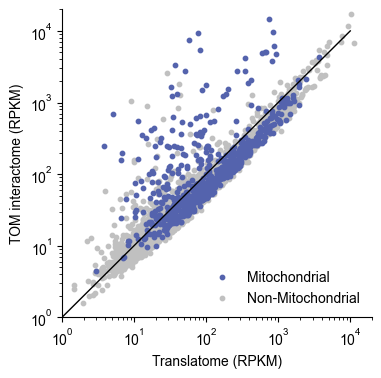

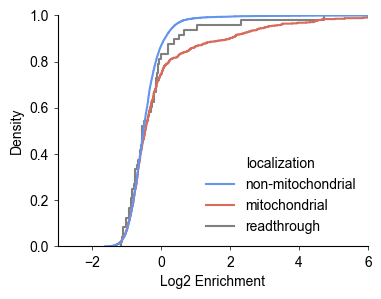

In [132]:
# Set plotting styles
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'Arial'

# Load RPKM data
data = final
x_value = f"avg_{group1}_RPKM"
y_value = f"avg_{group2}_RPKM"

# Create scatter plot
plt.figure(figsize=(4, 4))

# Plot non-mitochondrial genes
non_mito_mask = data['localization'] != 'mitochondrial'
fig1 = plt.scatter(data.loc[non_mito_mask, x_value],
                   data.loc[non_mito_mask, y_value],
                   color='silver', edgecolor='silver', s=10, alpha=1)

# Plot mitochondrial genes
mito_mask = data['localization'] == 'mitochondrial'
fig2 = plt.scatter(data.loc[mito_mask, x_value],
                   data.loc[mito_mask, y_value],
                   color='#5463ad', edgecolor='#5463ad', s=10, alpha=1)

# Style axes
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(bottom=True, left=True)

# Labels and scales
plt.xlabel('Translatome (RPKM)', fontsize=10)
plt.ylabel('TOM interactome (RPKM)', fontsize=10)
plt.xscale('log')
plt.yscale('log')

# Diagonal reference line
plt.plot([1, 10000], [1, 10000], color='black', linewidth=1)

# Axis limits
plt.xlim(1, 20000)
plt.ylim(1, 20000)

# Legend
legend = ax.legend((fig2, fig1), ['Mitochondrial', 'Non-Mitochondrial'],
                   prop={'size': 10}, loc='lower right')
legend.get_frame().set_linewidth(0.0)
plt.savefig(
    f"{directory_path}/without_chx/scatter_avg_RPKM_median.png",
    dpi=600,
    bbox_inches='tight'
)


plt.show()


# Load Log2 enrichment data
data = filtered_gene_loc_df
# Define x-axis value
x_value = 'Log2_ratio'

# Plot ECDF
fig, ax = plt.subplots(figsize=(4, 3))
sns.ecdfplot(data=data,
             x=x_value,
             hue='localization',
             palette=['cornflowerblue', '#D66C5C', 'grey'],
             complementary=False)

# Style axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel('Density', fontsize=10)
ax.set_xlabel('Log2 Enrichment', fontsize=10)
ax.tick_params(bottom=True, left=True, width=0.5)
ax.tick_params(axis='both', labelsize=10, width=0.5, length=3)

# Legend
legend = ax.get_legend()
legend.get_frame().set_linewidth(0.0)

# Axis limits
ax.set_xlim(-3, 6)

plt.show()

Examine the three nucleotides periodicity for translatome

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def plot_mean_mito_enrichment():

    mito_genes = [
        g for g, loc in gene_localization.items()
        if loc == 'mitochondrial'
        and g in p1
        and g in p2
    ]

    all_profiles = []

    for gene in mito_genes:

        try:
            x, y1, y2, enrich, _ = gene_enrichment(gene)

            # convert to relative CDS %
            x_rel = np.array(x) / max(x)

            bins = np.linspace(0, 1, 101)

            binned = []

            for i in range(len(bins)-1):
                mask = (x_rel >= bins[i]) & (x_rel < bins[i+1])

                if mask.sum():
                    binned.append(np.nanmean(np.array(enrich)[mask]))
                else:
                    binned.append(np.nan)

            all_profiles.append(binned)

        except:
            continue

    mean_profile = np.nanmean(all_profiles, axis=0)

    plt.figure(figsize=(5,4))

    plt.plot(
        np.arange(1,101),
        mean_profile
    )

    plt.xlabel("% CDS")
    plt.ylabel("Mean TOM enrichment")
    plt.title("Mitochondrial genes")

    plt.show()

plot_mean_mito_enrichment()

NameError: name 'gene_localization' is not defined

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

plt.rcParams['font.family'] = 'Arial'

# --------------------------------------------------
# Load the two datasets
# --------------------------------------------------

without_chx = pd.read_csv(
    "without_chx/merged_avg_RPKM_median.csv"
)

with_chx = pd.read_csv(
    "with_chx/merged_avg_RPKM_median.csv"
)

# --------------------------------------------------
# Keep required columns
# --------------------------------------------------

without_chx = without_chx[
    ['gene', 'localization', 'Log2_ratio']
].rename(columns={
    'Log2_ratio': 'without_chx'
})

with_chx = with_chx[
    ['gene', 'Log2_ratio']
].rename(columns={
    'Log2_ratio': 'with_chx'
})

# --------------------------------------------------
# Keep only common genes
# --------------------------------------------------

df = pd.merge(
    without_chx,
    with_chx,
    on='gene',
    how='inner'
)

print("Genes in without_chx:", len(without_chx))
print("Genes in with_chx:", len(with_chx))
print("Common genes:", len(df))

# --------------------------------------------------
# Remove missing / infinite values
# --------------------------------------------------

df = df.replace([float('inf'), float('-inf')], pd.NA)

df = df.dropna(
    subset=['without_chx', 'with_chx']
)

print("Common genes after removing NA:", len(df))

# --------------------------------------------------
# Pearson correlation
# --------------------------------------------------

r, p = pearsonr(
    df['without_chx'],
    df['with_chx']
)

print(f"Pearson r = {r:.3f}")
print(f"P-value = {p:.3e}")

# --------------------------------------------------
# Split by localization
# --------------------------------------------------

non = df[df['localization'] == 'non-mitochondrial']
mito = df[df['localization'] == 'mitochondrial']
read = df[df['localization'] == 'readthrough']



Genes in without_chx: 5099
Genes in with_chx: 4860
Common genes: 4291
Common genes after removing NA: 4291
Pearson r = 0.668
P-value = 0.000e+00


In [22]:
df.to_csv("log2_correlation.csv", index=False)

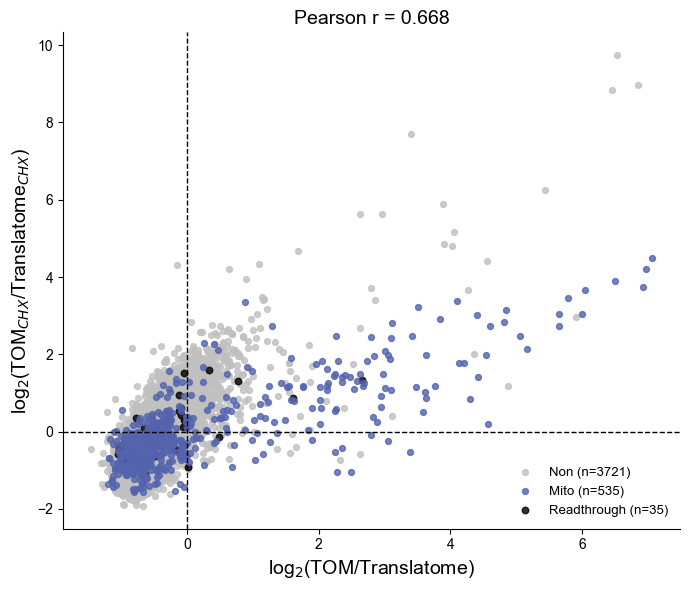

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
plt.rcParams['font.family'] = 'Arial'
# --- Load data ---
df = pd.read_csv("log2_correlation.csv")

# --- Compute Pearson correlation (on the without_chx vs with_chx values) ---
r, p = pearsonr(df["without_chx"], df["with_chx"])

# --- Split by category ---
non = df[df["localization"] == "non-mitochondrial"]
mito = df[df["localization"] == "mitochondrial"]
read = df[df["localization"] == "readthrough"]

# --- Plot ---
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(non["without_chx"], non["with_chx"],
           s=18, color="silver",edgecolor ="silver", alpha=0.8, label=f"Non (n={len(non)})",
           zorder=1)
ax.scatter(mito["without_chx"], mito["with_chx"],
           s=18, color="#5463ad", edgecolor="#5463ad",alpha=0.8, label=f"Mito (n={len(mito)})",
           zorder=2)
ax.scatter(read["without_chx"], read["with_chx"],
           s=22, color="black", alpha=0.8, label=f"Readthrough (n={len(read)})")

# Reference lines at x=0 and y=0
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(0, color="black", linestyle="--", linewidth=1)

# Labels & title
ax.set_xlabel(r"log$_2$(TOM/Translatome)", fontsize=14)
ax.set_ylabel(r"log$_2$(TOM$_{CHX}$/Translatome$_{CHX}$)", fontsize=14)

ax.set_title(f"Pearson r = {r:.3f}", fontsize=14)

# Legend
ax.legend(loc="lower right", frameon=False, fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# for spine in ax.spines.values():
#     spine.set_visible(True)

plt.tight_layout()
plt.savefig("log2_correlation_plot.png", dpi=600)

plt.show()

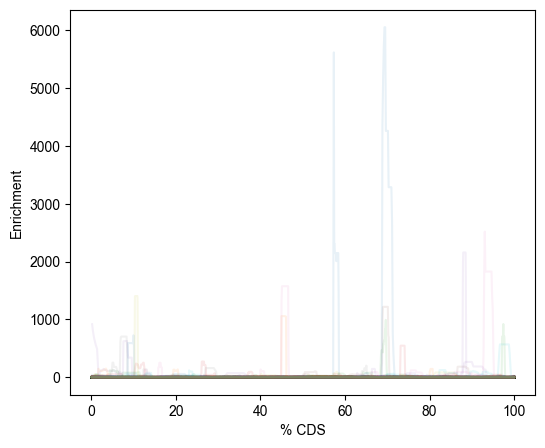

In [37]:
plt.figure(figsize=(6,5))

for gene, loc in gene_localization.items():

    if loc == 'mitochondrial' and gene in p1 and gene in p2:

        try:
            x, _, _, enrich, _ = gene_enrichment(gene)

            x_rel = np.array(x)/max(x)*100

            plt.plot(
                x_rel,
                enrich,
                alpha=0.1
            )

        except:
            pass

plt.xlabel("% CDS")
plt.ylabel("Enrichment")

plt.show()

In [38]:
mito_genes = [
    g for g in gene_localization
    if (
        gene_localization[g] == 'mitochondrial'
        and g in p1
        and g in p2
    )
]

p1_total = sum(p1[g][1].sum() for g in mito_genes)
p2_total = sum(p2[g][1].sum() for g in mito_genes)

length_total = sum(
    int(p1[g].attrs['cds_length'])
    for g in mito_genes
)

p1_rpkm = calculate_rpkm(
    p1_total,
    p1_Total_Reads,
    length_total
)

p2_rpkm = calculate_rpkm(
    p2_total,
    p2_Total_Reads,
    length_total
)

mito_enrichment = p2_rpkm / p1_rpkm

print("Combined mito enrichment:", mito_enrichment)
print("Log2:", np.log2(mito_enrichment))

Combined mito enrichment: 2.188823013207864
Log2: 1.1301553038609014


In [31]:
def three_nt_periodicity(group):
    end = 150
    codon_positions = range(1, end + 1)
    read_counts = {i: 0 for i in codon_positions}
    position_counts = {i: 0 for i in codon_positions}

    total_genes = 0
    p = p1 if group == group1 else p2
    total_reads = p1_Total_Reads if group == group1 else p2_Total_Reads

    for gene, data in p.items():
        cds_length = int(data.attrs['cds_length'])
        norm_factor = sum(data[1]) / cds_length

        if norm_factor >= 0.5:
            total_genes += 1
            for pos in codon_positions:
                if pos in data[0]:
                    index = data[0].tolist().index(pos)
                    nt_reads = data[1][index]
                    norm_reads = nt_reads / norm_factor / 3

                    read_counts[pos] += norm_reads
                    position_counts[pos] += 1

    # Calculate normalized read counts
    normalized_reads = {
        pos: read_counts[pos] / position_counts[pos]
        for pos in codon_positions if position_counts[pos] > 0
    }

    # Convert to DataFrame and save
    three_nt_df = pd.DataFrame.from_dict(normalized_reads, orient='index', columns=['normalized_read_count'])
    three_nt_df.index.name = 'codon'
    three_nt_df.to_csv(f'{directory_path}/three_nt_{group}.csv')

    return three_nt_df



(0.0, 150.0)

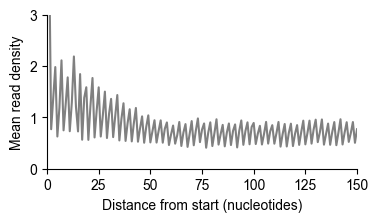

In [32]:
group = 'p1'
data = three_nt_periodicity(group)
x = data.index
y = data['normalized_read_count']

plt.figure(figsize=(4, 2))
plt.plot(x,y, color = 'grey')
plt.xlabel('Distance from start (nucleotides)')
plt.ylabel('Mean read density')

ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(bottom="on", left="on")

plt.ylim(0, 3)
plt.xlim(0, 150)


In [ ]:
def heatmap_start_codon():
    min_RPC = 0.25
    scores_dict = {}
    data = pd.read_csv(directory_path + '/Mito_gene_enrichment_list.csv')
    data = data[(data['p1_norm'] >= min_RPC) | (data['p2_norm'] >= min_RPC)]
    data.to_csv(directory_path + '/Mito_gene_enrichment_list_threshold.csv', index=False)

    data = data[['Log2_ratio','SubMitoLocalization','gene', 'Length', 'UniProt', 'MTS?']].copy()
    data = data.drop_duplicates(subset='gene', keep='first')

    for gene in data['gene'].unique():
        cache_filename = f"{directory_path}/genes/{gene}.pkl"
        if os.path.exists(cache_filename):
            with open(cache_filename, 'rb') as f:
                y_data = pickle.load(f)
        else:
            os.makedirs(os.path.dirname(cache_filename), exist_ok=True)  # This line ensures the directory exists
            y_data = gene_enrichment(gene)
            if not y_data:  # Check if y3_data is empty or None, implying the gene does not exist
                print(f"Skipping {gene} as it does not exist.")
                data = data[data['gene'] != gene]
                continue  # Skip to the next iteration of the loop
            else:       
                with open(cache_filename, 'wb') as f:
                    pickle.dump(y_data, f)    
            
        y3_data = y_data[3]
        scores_dict[gene] = {i: np.log2(score) for i, score in enumerate(y3_data)}
    # Convert the scores dictionary into a DataFrame
    score_data = pd.DataFrame(scores_dict).transpose()

    # Concatenate the original data and the score data
    data.set_index('gene', inplace=True)
    data = pd.concat([data, score_data], axis=1)

    return data


In [441]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'

# Generate codon-level heatmap data
heatmap_df_mito = heatmap_start_codon()

# Limit to first 1000 codons, reset index
df = heatmap_df_mito.iloc[:, :1000].copy()
df.reset_index(inplace=True)
df = df.rename(columns={'index': 'gene'})

# Filter for MTS-positive genes
df = df[df['MTS?'] == 'yes']

# Sort by gene length and clean columns
df = df.sort_values(by='Length')
df = df.set_index('gene')
df = df.drop(columns=['SubMitoLocalization', 'Length', 'UniProt', 'MTS?'])

# Create a mask for NaN values
nan_mask = np.isnan(df)

# Custom colormap (white for NaNs)
cmap = plt.get_cmap('RdBu_r')
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(3, 2.6))

sns.heatmap(
    df,
    vmin=-2.5, vmax=2.5,
    yticklabels=False,
    cmap=cmap,
    mask=nan_mask,
    cbar=False,
    ax=ax,
    cbar_kws={"shrink": 0.15, "aspect": 4}
)

# Style spines
for _, spine in ax.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(1)

# Style ticks
tick_positions = np.arange(0, 1000 + 1, 200)
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_positions, rotation=0, color='black', size=10)
ax.tick_params(width=1)

# Axis labels
ax.set_xlabel('Codon/amino acids', fontsize=10, color='black')
ax.set_ylabel('Gene', fontsize=10, color='black')

plt.show()


NameError: name 'heatmap_start_codon' is not defined

Metagene plot

In [ ]:
# Helper function to get the path where results for a gene are saved
def get_nt_to_codon_path(gene, p_type, directory_path):
    filename = f"{gene}_{p_type}.pkl"
    return os.path.join(directory_path, "genes", filename)  # Added "genes" subdirectory

def cached_nt_to_codon(p_type, gene, directory_path):
    file_path = get_nt_to_codon_path(gene, p_type, directory_path)
    
    if os.path.exists(file_path):
        with open(file_path, "rb") as file:
            return pickle.load(file)
    
    # Ensure the directory exists before attempting to write
    os.makedirs(os.path.dirname(file_path), exist_ok=True)  # This line ensures the directory exists
    
    result = nt_to_codon(p_type, gene)
    with open(file_path, "wb") as file:
        pickle.dump(result, file)
    
    return result

def initialize_dict(codons, keys=None):
    if not keys:
        return {i: [] for i in codons}
    else:
        return {key: [] for key in keys}

def calculate_mean_and_CI(codon_dict, full_dict, mean_key, upper_key, lower_key, confidence_interval, codons):
    for i in codons:
        resampled_means = [np.nanmean(resample(codon_dict[i], n_samples=len(codon_dict[i]))) for _ in range(100)]
        full_dict[mean_key].append(np.nanmean(codon_dict[i]))
        
        lower_quantile = np.quantile(resampled_means, 0.5 * (1 - confidence_interval))
        upper_quantile = np.quantile(resampled_means, 1 - 0.5 * (1 - confidence_interval))
        
        full_dict[upper_key].append(lower_quantile)
        full_dict[lower_key].append(upper_quantile)

def metagene_start_codon(localization, end, directory_path):
    codons = list(range(1, end + 1))
    codon_dict1 = initialize_dict(codons)
    codon_dict2 = initialize_dict(codons)
    min_RPC = 0.25

    df = pd.read_csv(f'{directory_path}gene_enrichment_list.csv')
    df = df[df['localization'] == localization]
    df = df[(df['p1_norm'] >= min_RPC) | (df['p2_norm'] >= min_RPC)]
    # df = df[(df['p1_norm'] >= min_RPC) | (df['p2_norm'] >= min_RPC)]
    # df = df[df['Length'] >= 300]

    num = 0
    for _, row in df.iterrows():
        gene = row.iloc[0]
        codon_length = row['Length']
        p1_norm = row['p1_norm']
        p2_norm = row['p2_norm']
    
        Dict1 = cached_nt_to_codon('p1', gene, directory_path)
        Dict2 = cached_nt_to_codon('p2', gene, directory_path)
        
        num += 1
        
        for k in range(1, min(codon_length, end) + 1):
            codon_dict1[k].append(Dict1.get(k, 0.01) / p1_norm)
            codon_dict2[k].append(Dict2.get(k, 0.01) / p2_norm)

    confidence_interval = 0.95
    keys = ['mean1', 'CI_upper1', 'CI_lower1', 'mean2', 'CI_upper2', 'CI_lower2']
    full_dict = initialize_dict(keys)

    calculate_mean_and_CI(codon_dict1, full_dict, 'mean1', 'CI_upper1', 'CI_lower1', confidence_interval, codons)
    calculate_mean_and_CI(codon_dict2, full_dict, 'mean2', 'CI_upper2', 'CI_lower2', confidence_interval, codons)


    metagene_df = pd.DataFrame(full_dict)
    metagene_df.to_csv(f'{directory_path}{localization}_metagene_start_codon.csv', index=None)
    print(num)
    return full_dict

In [ ]:
end = 600
localization = 'mitochondria'

meta_Dict = metagene_start_codon(localization, end, directory_path)


In [ ]:
# Load precomputed CSV
data = pd.read_csv(f'{directory_path}/{localization}_metagene_start_codon.csv')
x = range(1, end + 1)

color1 = 'grey'
color2 = 'darkblue'

plt.figure(figsize=(4, 3))

# Plot mean curves
plt.plot(x, data['mean1'], color=color1, linewidth=1)
plt.plot(x, data['mean2'], color=color2, linewidth=1)

# Plot confidence intervals
plt.fill_between(x, data['CI_upper1'], data['CI_lower1'], color=color1, alpha=0.3)
plt.fill_between(x, data['CI_upper2'], data['CI_lower2'], color=color2, alpha=0.3)

# Axes limits and labels
plt.xlim(0, 550)
plt.ylim(0, 3)
plt.xlabel('Codon from start (amino acids)', fontsize=10)
plt.ylabel('Ribosome density (AU)', fontsize=10)

# Legend
legend = plt.legend(['Translatome', 'TOM22 interactome'], loc='upper left')
legend.get_frame().set_linewidth(0.0)

# Clean up spines and ticks
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(bottom=True, left=True, width=0.5)

# Save or show
plt.show()


In [33]:
import pandas as pd
# Load your CSV files
df1 = pd.read_csv('/Users/shubham/labwork/yeast/chx_rep1/gene_enrichment_list.csv')
df2 = pd.read_csv('/Users/shubham/labwork/yeast/chx_rep2/gene_enrichment_list.csv')
# df3 = pd.read_csv('/Users/shubham/labwork/yeast/rep3/gene_enrichment_list.csv')

In [43]:
common_genes = pd.merge(df1, df2, on="gene", how="inner")


In [44]:
print(len(common_genes))
common_genes.head()

11321


,gene,localization_x,Length_x,p1_count_x,p2_count_x,p1_RPKM_x,p2_RPKM_x,ratio_x,Log2_ratio_x,p1_norm_x,...,localization_y,Length_y,p1_count_y,p2_count_y,p1_RPKM_y,p2_RPKM_y,ratio_y,Log2_ratio_y,p1_norm_y,p2_norm_y
0,MYO7A,non_mitochondrial,2259,1,4119,0.047258,455.982596,9648.778652,13.236131,0.000443,...,non_mitochondrial,2259,1,2,0.047258,0.221405,4.685010,2.228052,0.000443,0.000885
1,CBARP,non_mitochondrial,828,58,4078,7.478075,1231.656464,164.702344,7.363717,0.070048,...,non_mitochondrial,828,70,21,9.025263,6.342517,0.702752,-0.508913,0.084541,0.025362
2,TRPM7,non_mitochondrial,1895,266,15938,14.985270,2103.281075,140.356567,7.132953,0.140369,...,non_mitochondrial,1895,520,34307,29.294513,4527.372558,154.546776,7.271900,0.274406,18.103958
3,ARHGAP6,non_mitochondrial,975,3,151,0.328480,38.729781,117.906092,6.881494,0.003077,...,non_mitochondrial,975,5,98,0.547466,25.135884,45.913101,5.520834,0.005128,0.100513
4,ANO9,non_mitochondrial,783,13,499,1.772449,159.371804,89.916159,6.490508,0.016603,...,non_mitochondrial,783,32,1138,4.362951,363.457141,83.305339,6.380337,0.040868,1.453384


In [15]:
# Load your CSV files
import pandas as pd
df1_th = pd.read_csv('/Users/shubham/labwork/yeast/rep1/gene_enrichment_list_threshold.csv')
df2_th = pd.read_csv('/Users/shubham/labwork/yeast/rep2/gene_enrichment_list_threshold.csv')
df3_th = pd.read_csv('/Users/shubham/labwork/yeast/rep3/gene_enrichment_list_threshold.csv')
#df3_th = pd.read_csv('/Users/shubham/Downloads/labwork/yeast/rep3/gene_enrichment_list_threshold.csv')

In [16]:
merged = df1_th.merge(df2_th, on="gene").merge(df3_th, on ="gene")
print(merged.shape)
merged.to_csv('/Users/shubham/labwork/yeast/rep1_2/without_chx/merged_rep1_2_3threshold.csv', index=False)


(4425, 31)


In [17]:
# Merge df1, df2, df3 on gene
merged = (
    df1_th.merge(df2_th, on="gene", suffixes=("_x", "_y"))
          .merge(df3_th, on="gene", suffixes=("", "_z"))
)

# Rename df3_th columns to have _z suffix except gene
df3_cols = {col: col + "_z" for col in df3_th.columns if col != "gene"}
merged = merged.rename(columns=df3_cols)

# Columns that should NOT be averaged
fixed_cols = ["gene", "localization", "Length"]

# Set these from _x (df1)
merged["localization"] = merged["localization_x"]
merged["Length"] = merged["Length_x"]

# Identify numeric columns to average
base_columns = ["p1_count", "p2_count", "p1_RPKM", "p2_RPKM",
                "ratio", "Log2_ratio", "p1_norm", "p2_norm"]

for base in base_columns:
    col_x = base + "_x"
    col_y = base + "_y"
    col_z = base + "_z"

    # Average across x, y, z
    merged[base] = merged[[col_x, col_y, col_z]].mean(axis=1)

# Columns to drop (all _x, _y, _z)
drop_cols = [c for c in merged.columns if c.endswith(("_x", "_y", "_z"))]
merged = merged.drop(columns=drop_cols)

# Save final file
merged.to_csv(
    "/Users/shubham/labwork/yeast/rep1_2/without_chx/merged_rep1_2_3_threshold_avg.csv",
    index=False
)

print("Final shape:", merged.shape)
print(merged.head())


Final shape: (4425, 11)
      gene       localization  Length     p1_count      p2_count    p1_RPKM  \
0  TRAPPC9  non_mitochondrial    1238   299.000000   4802.666667  15.064733   
1    IARS2      mitochondrial    1013  1291.666667  53398.666667  77.967444   
2    TRPM7  non_mitochondrial    1895   586.666667  22826.000000  28.893981   
3    UCKL1  non_mitochondrial     613   475.333333   3659.000000  44.035279   
4    LARS2      mitochondrial     904   585.666667  17561.000000  37.265085   

       p2_RPKM       ratio  Log2_ratio   p1_norm    p2_norm  
0   962.146265   55.732986    2.961363  0.241519   3.879375  
1  9854.282752  126.553812    6.982747  1.275090  52.713393  
2  2785.999525  113.393075    6.810626  0.309587  12.045383  
3  1375.398675   38.692864    3.638574  0.775421   5.969005  
4  3499.345382   93.082647    6.536333  0.647861  19.425885  


In [103]:
mmc = pd.read_excel("/users/shubham/Downloads/mmc1.xls")


In [104]:
print(mmc.head())

       gene   localization  CDS_length  Translatome_rep1_RPKM  \
0     IARS2  mitochondrial        1013              83.023661   
1      ACO2  mitochondrial         781              55.449345   
2     TRPM7             ER        1895              77.653258   
3     LARS2  mitochondrial         904              29.804749   
4  ALDH18A1  mitochondrial         830             100.014625   

   TOM_interactome_rep1_RPKM  Log2_TOM_enrichment_rep1  Translatome_rep2_RPKM  \
0               10110.445400                  6.928108              78.321847   
1                4429.902247                  6.319961              60.882346   
2                7256.665035                  6.546116               4.925658   
3                2543.837557                  6.415321              39.661513   
4                6896.471455                  6.107576              74.355439   

   TOM_interactome_rep2_RPKM  Log2_TOM_enrichment_rep2  \
0                9424.952902                  6.910927   
1     

In [105]:
p1_rpkm_cols = ["Translatome_rep1_RPKM", "Translatome_rep2_RPKM"]
# convert to numeric (important!)
mmc[p1_rpkm_cols] = mmc[p1_rpkm_cols].apply(pd.to_numeric, errors='coerce')
mmc["p1_rpkm_avg"] = mmc[p1_rpkm_cols].mean(axis=1)
p2_rpkm_cols = ["TOM_interactome_rep1_RPKM", "TOM_interactome_rep2_RPKM"]
# convert to numeric (important!)
mmc[p2_rpkm_cols] = mmc[p2_rpkm_cols].apply(pd.to_numeric, errors='coerce')
mmc["p2_rpkm_avg"] = mmc[p2_rpkm_cols].mean(axis=1)

In [125]:
p1_rpkm_cols = ["p1_RPKM_x", "p1_RPKM_y","p1_RPKM"]
# convert to numeric (important!)
merged[p1_rpkm_cols] = merged[p1_rpkm_cols].apply(pd.to_numeric, errors='coerce')
merged["p1_rpkm_avg"] = merged[p1_rpkm_cols].mean(axis=1)
p2_rpkm_cols = ["p2_RPKM_x", "p2_RPKM_y","p2_RPKM"]
# convert to numeric (important!)
merged[p2_rpkm_cols] = merged[p2_rpkm_cols].apply(pd.to_numeric, errors='coerce')
merged["p2_rpkm_avg"] = merged[p2_rpkm_cols].mean(axis=1)


In [126]:
merged.to_csv('/Users/shubham/Downloads/labwork/yeast/rep1/rep1_2_3.csv', index=False)

In [14]:
summary = merged['localization'].value_counts()
print(summary)

localization
non_mitochondrial    3887
mitochondrial         558
Name: count, dtype: int64


In [107]:
mmc.to_csv('/Users/shubham/Downloads/labwork/yeast/rep1/rep1_2_mmc.csv', index=False)


In [517]:
df1_common = df1[df1['gene'].isin(common_genes)][['gene', 'ratio','p1_RPKM']].rename(columns={'ratio': 'Enrichment_ratio_rep1','p1_RPKM': 'p1_RPKM_rep1'})
df2_common = df2[df2['gene'].isin(common_genes)][['gene', 'ratio','p1_RPKM']].rename(columns={'ratio': 'Enrichment_ratio_rep2','p1_RPKM': 'p1_RPKM_rep2'})
df3_common = df3[df3['gene'].isin(common_genes)][['gene', 'ratio','p1_RPKM']].rename(columns={'ratio': 'Enrichment_ratio_rep3','p1_RPKM': 'p1_RPKM_rep3'})

# Merge all on 'gene'
merged = df1_common.merge(df2_common, on='gene').merge(df3_common, on='gene')

In [518]:
print(merged.shape)

(11833, 7)


In [527]:

# Calculate average of p1_RPKM across all three files
merged['avg_p1_RPKM'] = merged[['p1_RPKM_rep1', 'p1_RPKM_rep1', 'p1_RPKM_rep1']].mean(axis=1)

# Save or display
merged.to_csv('/Users/shubham/Downloads/labwork/yeast/rep1/common_genes_with_ratios_and_avgRPKM.csv', index=False)
print(merged.head())

       gene  Enrichment_ratio_rep1  p1_RPKM_rep1  Enrichment_ratio_rep2  \
0     CDH26            1991.129365      0.238295               2.091632   
1  ARHGAP27            1773.276387      0.119951               6.100592   
2     SPEF2             887.809446      0.203539               0.542275   
3     SALL3             534.559672      0.410284               2.440237   
4      TLE6             400.568378      0.186311               3.660355   

   p1_RPKM_rep2  Enrichment_ratio_rep3  p1_RPKM_rep3  avg_p1_RPKM  
0      0.433556               1.381210      0.450729     0.238295  
1      0.187062               5.179536      0.145848     0.119951  
2      0.714190               0.998911      0.598872     0.203539  
3      0.127967            3067.839312      0.206945     0.410284  
4      0.290551               1.553861      0.156623     0.186311  


In [494]:
# extract_counts_from_h5.py
import h5py
import pandas as pd

# paths - change to your actual files
p1_path = f"{directory_path}Translatome_rep3.h5"    # translatome
p2_path = f"{directory_path}TOM_interactome_rep3.h5" # interactome

def h5_to_counts(path):
    counts = {}
    with h5py.File(path, 'r') as f:
        for gene in f.keys():
            data = f[gene][:]
            # data[1] = raw counts (per-position). sum -> gene raw count
            counts[gene] = int(data[1].sum())
    return counts

p1_counts = h5_to_counts(p1_path)
p2_counts = h5_to_counts(p2_path)

# keep intersection of genes present in both
genes = sorted(set(p1_counts.keys()).intersection(p2_counts.keys()))

df = pd.DataFrame({
    'gene': genes,
    'translatome': [p1_counts[g] for g in genes],
    'interactome': [p2_counts[g] for g in genes]
})

df = df.set_index('gene')
print("Wrote counts_matrix.tsv with shape:", df.shape)
print(df.head())


Wrote counts_matrix.tsv with shape: (13099, 2)
         translatome  interactome
gene                             
A1BG             153           36
A3GALT2            1            2
A4GALT            36            8
AAAS            1603          266
AACS             284           47


In [498]:
df_cpm = df.div(df.sum(axis=0), axis=1) * 1e6
df_log = np.log2(df_cpm + 1)


/Users/shubham/Library/Python/3.9/lib/python/site-packages/pandas/core/internals/blocks.py:395: RuntimeWarning: invalid value encountered in log2
  result = func(self.values, **kwargs)


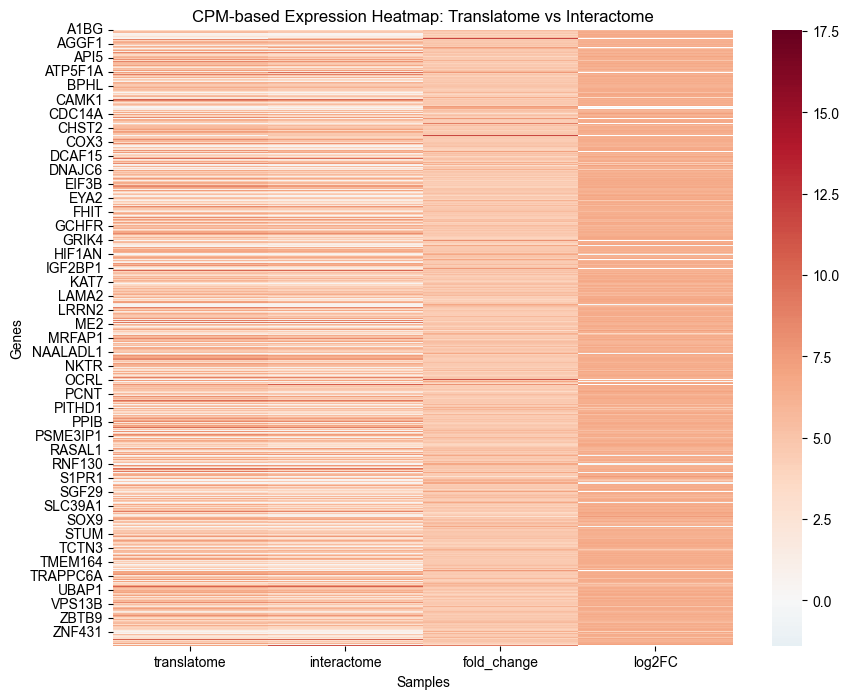

In [499]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(df_log, cmap='RdBu_r', center=0)
plt.title('CPM-based Expression Heatmap: Translatome vs Interactome')
plt.xlabel('Samples')
plt.ylabel('Genes')
plt.show()


ValueError: The condensed distance matrix must contain only finite values.

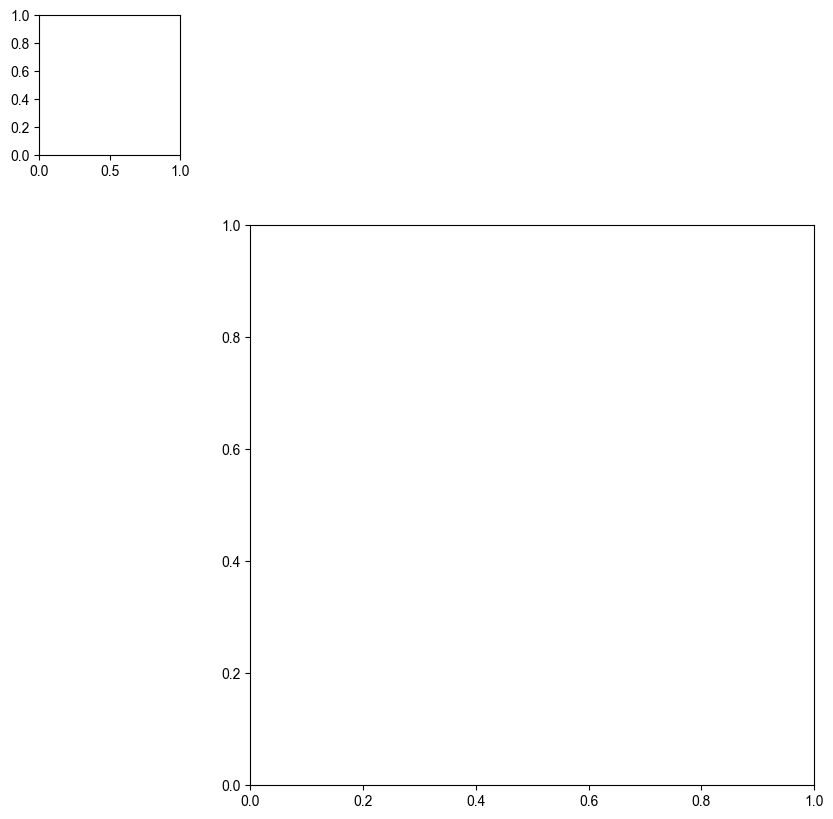

In [500]:
top_genes = df_log.var(axis=1).sort_values(ascending=False).head(50).index
sns.clustermap(df_log.loc[top_genes], cmap='RdBu_r', center=0, figsize=(10,10))


In [495]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# add small pseudocount to avoid div-by-zero (only for ranking; do NOT feed these to DESeq2)
pseudo = 0.1
df['fold_change'] = (df['interactome'] + pseudo) / (df['translatome'] + pseudo)
df['log2FC'] = np.log2(df['fold_change'])

# rank genes by absolute log2FC
top_up = df.sort_values('log2FC', ascending=False).head(20)
top_down = df.sort_values('log2FC').head(20)

# df.to_csv('counts_with_fc.tsv', sep='\t')
print("Saved counts_with_fc.tsv; top 5 by log2FC:")
print(df.sort_values('log2FC', ascending=False).head())


Saved counts_with_fc.tsv; top 5 by log2FC:
       translatome  interactome  fold_change     log2FC
gene                                                   
MYO7A            2         3731  1776.714286  10.794996
SALL3            6         5923   971.000000   9.923327
TGM6             3          964   311.000000   8.280771
MUC2             2          491   233.857143   7.869484
TLR4             1          241   219.181818   7.775984


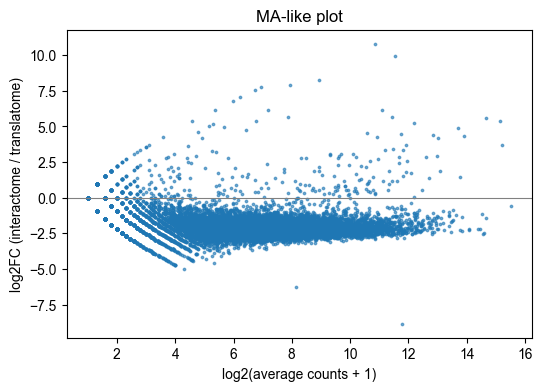

In [501]:
# MA plot (log-average vs log-fold change)
avg = np.log2((df['translatome'] + df['interactome'])/2 + 1)
plt.figure(figsize=(6,4))
plt.scatter(avg, df['log2FC'], s=3, alpha=0.6)
plt.axhline(0, color='gray', lw=0.8)
plt.xlabel('log2(average counts + 1)')
plt.ylabel('log2FC (interactome / translatome)')
plt.title('MA-like plot')
plt.show()


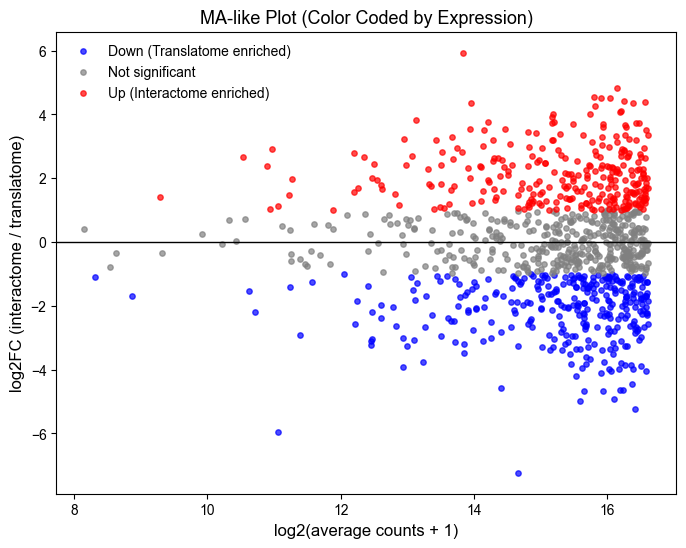

In [502]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Example dataframe (replace this with your data)
# Suppose df has two columns: 'avg_counts' and 'log2FC'
# avg_counts = mean of interactome + translatome counts
# log2FC = log2(interactome / translatome)
df = pd.DataFrame({
    'avg_counts': np.random.uniform(1, 1e5, 1000),
    'log2FC': np.random.normal(0, 2, 1000)
})

# Compute log2 average counts
df['log2_avg'] = np.log2(df['avg_counts'] + 1)

# Define thresholds for "highly expressed" (adjust as needed)
fc_threshold = 1     # |log2FC| > 1 means 2-fold change
df['status'] = 'Not significant'
df.loc[df['log2FC'] > fc_threshold, 'status'] = 'Up (Interactome enriched)'
df.loc[df['log2FC'] < -fc_threshold, 'status'] = 'Down (Translatome enriched)'

# Plot
plt.figure(figsize=(8,6))
colors = {'Up (Interactome enriched)': 'red',
          'Down (Translatome enriched)': 'blue',
          'Not significant': 'gray'}

for key, group in df.groupby('status'):
    plt.scatter(group['log2_avg'], group['log2FC'], 
                c=colors[key], label=key, s=15, alpha=0.7)

plt.axhline(0, color='black', linewidth=1)
plt.xlabel('log2(average counts + 1)', fontsize=12)
plt.ylabel('log2FC (interactome / translatome)', fontsize=12)
plt.title('MA-like Plot (Color Coded by Expression)', fontsize=13)
plt.legend(frameon=False)
plt.show()


In [4]:
path = '/Users/shubham/Downloads/labwork/yeast/rep1/'
import h5py
import pandas as pd

def load_h5_counts(path):
    f = h5py.File(path, "r")
    counts = f["counts"][:]              # raw count matrix
    genes = f["genes"][:].astype(str)    # gene names
    f.close()
    return pd.DataFrame(counts, index=genes, columns=[path])

a1 = load_h5_counts("TOM_interactome_rep1.h5")
a2 = load_h5_counts("Translatome_rep1.h5")



FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'TOM_interactome_rep1.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [8]:
import h5py

f = h5py.File("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5", "r")

def explore(name, obj):
    print(name, "→", type(obj), obj.keys() if isinstance(obj, h5py.Group) else "dataset")

f.visititems(explore)
f.close()



A1BG → <class 'h5py._hl.dataset.Dataset'> dataset
A2M → <class 'h5py._hl.dataset.Dataset'> dataset
A3GALT2 → <class 'h5py._hl.dataset.Dataset'> dataset
A4GALT → <class 'h5py._hl.dataset.Dataset'> dataset
AAAS → <class 'h5py._hl.dataset.Dataset'> dataset
AACS → <class 'h5py._hl.dataset.Dataset'> dataset
AADACL4 → <class 'h5py._hl.dataset.Dataset'> dataset
AADAT → <class 'h5py._hl.dataset.Dataset'> dataset
AAGAB → <class 'h5py._hl.dataset.Dataset'> dataset
AAK1 → <class 'h5py._hl.dataset.Dataset'> dataset
AAMDC → <class 'h5py._hl.dataset.Dataset'> dataset
AAMP → <class 'h5py._hl.dataset.Dataset'> dataset
AAR2 → <class 'h5py._hl.dataset.Dataset'> dataset
AARD → <class 'h5py._hl.dataset.Dataset'> dataset
AARS1 → <class 'h5py._hl.dataset.Dataset'> dataset
AARS2 → <class 'h5py._hl.dataset.Dataset'> dataset
AARSD1 → <class 'h5py._hl.dataset.Dataset'> dataset
AASDH → <class 'h5py._hl.dataset.Dataset'> dataset
AASDHPPT → <class 'h5py._hl.dataset.Dataset'> dataset
AASS → <class 'h5py._hl.dataset

In [15]:
import h5py
import pandas as pd

def load_gene_datasets(path):
    data = {}
    
    with h5py.File(path, "r") as f:
        for gene in f.keys():
            # read the dataset (likely a single value)
            value = f[gene][()]   # read entire dataset
            
            # HDF5 may return arrays; convert to python scalar
            if isinstance(value, (list, tuple)) or hasattr(value, "__len__"):
                if len(value) == 1:
                    value = value[0]
            
            data[gene] = value
    
    df = pd.DataFrame.from_dict(data, orient="index", columns=[path])
    return df
    
a1 = load_gene_datasets("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5")
a2 = load_gene_datasets("/Users/shubham/Downloads/labwork/yeast/rep1/Translatome_rep1.h5")

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (14062, 2) + inhomogeneous part.

In [16]:
import h5py

with h5py.File("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5", "r") as f:
    i = 0
    for gene in f.keys():
        print(gene, f[gene][()])
        i += 1
        if i == 10:
            break


A1BG [[1477 1459 1437 1420 1382 1361 1353 1335 1321 1309 1283 1271 1258 1254
  1253   75]
 [   1    1    1    1    1    1    1    1    1    1    2    1    1    1
     1    1]]
A2M [[2976]
 [   1]]
A3GALT2 [[655 654]
 [  1   1]]
A4GALT [[817 747  28]
 [  3   1   1]]
AAAS [[1672 1667 1660 1647 1638 1607 1602 1591 1567 1563 1500 1495 1486 1484
  1480 1458 1438 1431 1427 1423 1407 1405 1401 1384 1326 1320 1301 1294
  1270 1257 1251 1246 1233 1213 1167 1127 1108 1094 1083 1060 1045 1039
  1014 1011  995  994  987  965  949  943  937  933  919  916  913  910
   909  903  892  875  864  862  856  847  838  835  829  826  820  819
   813  808  796  791  788  761  757  743  741  736  732  730  729  721
   682  668  665  660  631  592  579  576  570  569  568  546  541  538
   531  514  492  463  445  403  399  397  395  389  384  372  352  325
   304  280  274  250  242  241  224  223  218  212  211  210  199  184
   182  177  176  175  160  157  129  102   67   42   39   36   33   29
    13   

In [19]:
import h5py
import pandas as pd
import os

def load_riboseq_counts(path):
    gene_counts = {}

    with h5py.File(path, "r") as f:
        for gene in f.keys():
            ds = f[gene][()]   # read 2-row matrix

            # ds shape is (2, N): row0 = positions, row1 = counts
            counts = ds[1]     # second row = p-site counts at each CDS position

            total = counts.sum()
            gene_counts[gene] = total

    df = pd.DataFrame.from_dict(gene_counts, orient="index", columns=[os.path.basename(path)])
    return df


# LOAD YOUR FILES
rep1 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep1/Translatome_rep1.h5")
rep2 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep2/Translatome_rep2.h5")
rep3 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep3/Translatome_rep3.h5")
cond1_rep1 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5")
cond1_rep2 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep2/TOM_interactome_rep2.h5")
cond1_rep3 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep3/TOM_interactome_rep3.h5")

# MERGE INTO COUNT MATRIX
counts = pd.concat([rep1, cond1_rep1,rep2,cond1_rep2,rep3,cond1_rep3], axis=1).fillna(0)
print(counts.head())


        Translatome_rep1.h5  TOM_interactome_rep1.h5  Translatome_rep2.h5  \
A1BG                   53.0                     17.0                131.0   
A2M                     1.0                      1.0                  0.0   
A4GALT                 13.0                      5.0                 32.0   
AAAS                  449.0                    163.0               1355.0   
AACS                  120.0                     39.0                255.0   

        TOM_interactome_rep2.h5  Translatome_rep3.h5  TOM_interactome_rep3.h5  
A1BG                       27.0                153.0                     36.0  
A2M                         0.0                  1.0                      0.0  
A4GALT                      4.0                 36.0                      8.0  
AAAS                      219.0               1603.0                    266.0  
AACS                       55.0                284.0                     47.0  


In [20]:
counts.to_csv("/Users/shubham/Downloads/labwork/yeast/rep1/counts.csv")

In [21]:
print(counts)

         Translatome_rep1.h5  TOM_interactome_rep1.h5  Translatome_rep2.h5  \
A1BG                    53.0                     17.0                131.0   
A2M                      1.0                      1.0                  0.0   
A4GALT                  13.0                      5.0                 32.0   
AAAS                   449.0                    163.0               1355.0   
AACS                   120.0                     39.0                255.0   
...                      ...                      ...                  ...   
ZNF334                   0.0                      0.0                  0.0   
ZNF354C                  0.0                      0.0                  0.0   
ZNF474                   0.0                      0.0                  0.0   
ZNF804B                  0.0                      0.0                  0.0   
ZNF883                   0.0                      0.0                  0.0   

         TOM_interactome_rep2.h5  Translatome_rep3.h5  TOM_inte

In [31]:
import h5py
import pandas as pd
import os
h5_path = '/Users/shubham/Downloads/labwork/yeast/rep1/'
def load_riboseq_counts(h5_path):
    gene_counts = {}

    with h5py.File(h5_path, "r") as f:
        for gene in f.keys():
            ds = f[gene][()]   # read 2-row matrix

            # ds shape is (2, N): row0 = positions, row1 = counts
            counts = ds[1]     # second row = p-site counts at each CDS position

            total = counts.sum()
            gene_counts[gene] = total

    df = pd.DataFrame.from_dict(gene_counts, orient="index", columns=[os.path.basename(h5_path)])
    return df


# LOAD YOUR FILES
rep1 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep1/Translatome_rep1.h5")
rep2 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep2/Translatome_rep2.h5")
rep3 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep3/Translatome_rep3.h5")
cond1_rep1 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5")
cond1_rep2 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep2/TOM_interactome_rep2.h5")
cond1_rep3 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep3/TOM_interactome_rep3.h5")


# MERGE INTO COUNT MATRIX
counts = pd.concat([rep1, cond1_rep1, rep2, cond1_rep2, rep3, cond1_rep3], axis=1).fillna(0)
print(counts.head())


        Translatome_rep1.h5  TOM_interactome_rep1.h5  Translatome_rep2.h5  \
A1BG                   53.0                     17.0                131.0   
A2M                     1.0                      1.0                  0.0   
A4GALT                 13.0                      5.0                 32.0   
AAAS                  449.0                    163.0               1355.0   
AACS                  120.0                     39.0                255.0   

        TOM_interactome_rep2.h5  Translatome_rep3.h5  TOM_interactome_rep3.h5  
A1BG                       27.0                153.0                     36.0  
A2M                         0.0                  1.0                      0.0  
A4GALT                      4.0                 36.0                      8.0  
AAAS                      219.0               1603.0                    266.0  
AACS                       55.0                284.0                     47.0  


In [29]:
print(counts.shape)

(16170, 6)


In [30]:
counts.to_csv("/Users/shubham/Downloads/labwork/yeast/rep1/counts.csv")

In [33]:
rep1 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5")
rep2 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep2/TOM_interactome_rep2.h5")
rep3 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep3/TOM_interactome_rep3.h5")
cond1 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_CHX_rep1.h5")
cond2 = load_riboseq_counts("/Users/shubham/Downloads/labwork/yeast/rep2/TOM_interactome_CHX_rep2.h5")
counts = pd.concat([rep1, cond1, rep2, cond2, rep3], axis=1).fillna(0)
print(counts.head())


         TOM_interactome_rep1.h5  TOM_interactome_CHX_rep1.h5  \
A1BG                        17.0                         15.0   
A2M                          1.0                          2.0   
A3GALT2                      2.0                          7.0   
A4GALT                       5.0                          2.0   
AAAS                       163.0                         35.0   

         TOM_interactome_rep2.h5  TOM_interactome_CHX_rep2.h5  \
A1BG                        27.0                         17.0   
A2M                          0.0                          0.0   
A3GALT2                      3.0                          0.0   
A4GALT                       4.0                          4.0   
AAAS                       219.0                         39.0   

         TOM_interactome_rep3.h5  
A1BG                        36.0  
A2M                          0.0  
A3GALT2                      2.0  
A4GALT                       8.0  
AAAS                       266.0  


In [34]:
counts.to_csv("/Users/shubham/Downloads/labwork/yeast/rep1/counts_chx.csv")

In [12]:
import h5py

with h5py.File("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5","r") as h5:
    print("Top-level keys:", list(h5.keys()))
import h5py

def show_tree(name, obj):
    print(name, " → ", type(obj))
    if isinstance(obj, h5py.Group):
        print("   attrs:", list(obj.attrs.keys()))
        print("   children:", list(obj.keys()))

with h5py.File("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5","r") as h5:
    h5.visititems(show_tree)


Top-level keys: ['A1BG', 'A2M', 'A3GALT2', 'A4GALT', 'AAAS', 'AACS', 'AADACL4', 'AADAT', 'AAGAB', 'AAK1', 'AAMDC', 'AAMP', 'AAR2', 'AARD', 'AARS1', 'AARS2', 'AARSD1', 'AASDH', 'AASDHPPT', 'AASS', 'AATF', 'AATK', 'ABAT', 'ABCA1', 'ABCA10', 'ABCA12', 'ABCA13', 'ABCA2', 'ABCA3', 'ABCA4', 'ABCA5', 'ABCA7', 'ABCA8', 'ABCB1', 'ABCB10', 'ABCB4', 'ABCB6', 'ABCB7', 'ABCB8', 'ABCB9', 'ABCC1', 'ABCC10', 'ABCC2', 'ABCC3', 'ABCC4', 'ABCC5', 'ABCC8', 'ABCC9', 'ABCD1', 'ABCD2', 'ABCD3', 'ABCD4', 'ABCE1', 'ABCF2', 'ABCF2-H2BE1', 'ABCF3', 'ABCG1', 'ABCG2', 'ABCG4', 'ABHD1', 'ABHD10', 'ABHD11', 'ABHD12', 'ABHD13', 'ABHD14A', 'ABHD14A-ACY1', 'ABHD14B', 'ABHD15', 'ABHD17B', 'ABHD17C', 'ABHD18', 'ABHD2', 'ABHD3', 'ABHD4', 'ABHD5', 'ABHD6', 'ABHD8', 'ABI1', 'ABI2', 'ABI3', 'ABI3BP', 'ABITRAM', 'ABL1', 'ABL2', 'ABLIM1', 'ABLIM2', 'ABLIM3', 'ABO', 'ABR', 'ABRACL', 'ABRAXAS1', 'ABRAXAS2', 'ABT1', 'ABTB1', 'ABTB2', 'ACAA1', 'ACAA2', 'ACACA', 'ACACB', 'ACAD10', 'ACAD11', 'ACAD8', 'ACAD9', 'ACADL', 'ACADM', 'ACAD

In [13]:
import h5py

results = {}

with h5py.File("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5", "r") as h5:

    for gene_name in h5.keys():   # each key = gene dataset
        entry = h5[gene_name]     # dataset

        # extract attributes
        attrs = entry.attrs
        
        cds_length = int(attrs["cds_length"])
        gene = attrs["gene"].decode()   # this should match gene_name
        # you can decode others if needed
        
        # extract counts
        counts = entry[:]   # dataset content itself

        results[gene] = {
            "cds_length": cds_length,
            "counts": counts
        }


In [16]:
print(results["A1BG"])

{'cds_length': 1488, 'counts': array([[1477, 1459, 1437, 1420, 1382, 1361, 1353, 1335, 1321, 1309, 1283,
        1271, 1258, 1254, 1253,   75],
       [   1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    2,
           1,    1,    1,    1,    1]], dtype=uint32)}


In [17]:
import h5py

all_results = {}

with h5py.File("/Users/shubham/Downloads/labwork/yeast/rep1/TOM_interactome_rep1.h5", "r") as h5:

    for gene_name in h5.keys():
        entry = h5[gene_name]

        cds_length = int(entry.attrs["cds_length"])
        counts = entry[:]      # 2 × cds_length matrix

        all_results[gene_name] = {
            "cds_length": cds_length,
            "counts": counts   # shape (2, cds_length)
        }


In [18]:
print("Genes extracted:", len(all_results))
first_gene = list(all_results.keys())[0]
print("Example gene:", first_gene)
print(all_results[first_gene]["cds_length"])
print(all_results[first_gene]["counts"].shape)


Genes extracted: 14062
Example gene: A1BG
1488
(2, 16)


In [42]:
import pandas as pd

rows = []

for gene, data in all_results.items():
    cds_len = data["cds_length"]
    counts = data["counts"]   # shape (2, N)

    positions = counts[0]     # actual CDS positions
    counts_values = counts[1] # counts at those positions

    for pos, count in zip(positions, counts_values):
        rows.append([gene, cds_len, int(pos), int(count)])

# create DataFrame
df = pd.DataFrame(rows, columns=["gene", "cds_length", "cds_position", "count"])


In [44]:
print(df.shape
     )

(730106, 4)


In [49]:
df_sorted = df.sort_values(by=["gene", "cds_position"])
# Compute the interval to previous position
df_sorted["interval"] = df_sorted.groupby("gene")["cds_position"].diff()

# The first position per gene will have NaN
df_sorted["interval"] = df_sorted["interval"].fillna(0).astype(int)
print(df_sorted.head())
print(df_sorted.shape)

    gene  cds_length  cds_position  count  interval
15  A1BG        1488            75      1         0
14  A1BG        1488          1253      1      1178
13  A1BG        1488          1254      1         1
12  A1BG        1488          1258      1         4
11  A1BG        1488          1271      1        13
(730106, 5)


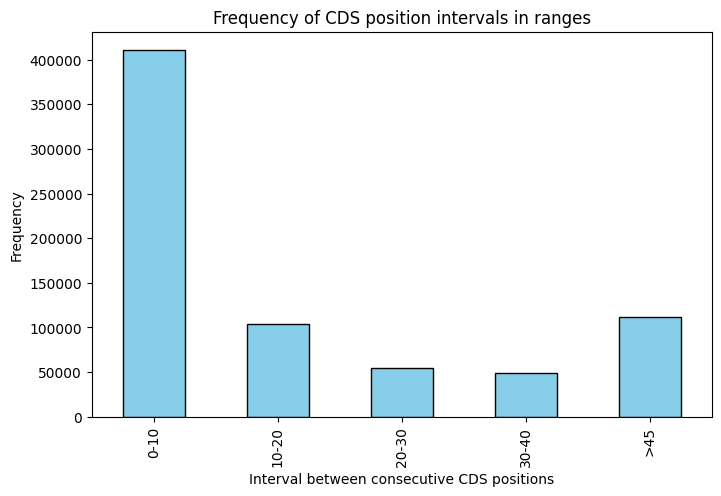

In [79]:
import matplotlib.pyplot as plt
import pandas as pd

# Define bins and labels
bins = [0, 10, 20, 30, 45, float('inf')]
labels = ["0-10", "10-20", "20-30", "30-40", ">45"]

# Create a new column with the interval bin
df_sorted["interval_range"] = pd.cut(df_sorted["interval"], bins=bins, labels=labels, right=False)

# Count frequency in each range
freq = df_sorted["interval_range"].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
freq.plot(kind="bar", color="skyblue", edgecolor="black")
plt.xlabel("Interval between consecutive CDS positions")
plt.ylabel("Frequency")
plt.title("Frequency of CDS position intervals in ranges")
plt.show()


In [54]:
import pandas as pd

# Example: take one gene
gene_name = "A1BG"
gene_df = df_sorted[df_sorted["gene"] == gene_name].copy()

# Step 1: calculate intervals between consecutive positions
gene_df = gene_df.sort_values("cds_position")
gene_df["interval"] = gene_df["cds_position"].diff().fillna(0).astype(int)

# Step 2: define bins
bins = [0, 10, 20, 30, 35, float('inf')]
labels = ["0-10", "10-20", "20-30", "30-35", ">35"]

# Step 3: bin the intervals
gene_df["interval_range"] = pd.cut(gene_df["interval"], bins=bins, labels=labels, right=False)

# Step 4: sum counts per interval
bin_counts = gene_df.groupby("interval_range", observed=True)["count"].sum().sort_index()


# Step 5: calculate cumulative fraction
cum_frac = bin_counts.cumsum() / bin_counts.sum()

# Step 6: find bins covering 90% of counts
bins_90 = cum_frac[cum_frac <= 0.9].index.tolist()

print(f"Gene {gene_name} — bins covering 90% of counts: {bins_90}")


Gene A1BG — bins covering 90% of counts: ['0-10', '10-20', '20-30']


In [87]:
import pandas as pd

# Define bins
bins = [0, 10, 20, 30, 40, float('inf')]
labels = ["0-10", "10-20", "20-30", "30-40", ">40"]

results = []

for gene, group in df_sorted.groupby("gene"):
    g = group.copy()
    
    # Sort CDS positions
    g = g.sort_values("cds_position")
    
    # Calculate interval
    g["interval"] = g["cds_position"].diff().fillna(0).astype(int)
    
    # Bin intervals
    g["interval_range"] = pd.cut(
        g["interval"],
        bins=bins,
        labels=labels,
        right=False
    )
    
    # Sum counts per bin
    bin_counts = g.groupby("interval_range", observed=True)["count"].sum().sort_index()
    
    # Cumulative fraction
    cum_frac = bin_counts.cumsum() / bin_counts.sum()
    
    # Bins that cover ≤ 90%
    bins_90 = cum_frac[cum_frac <= 0.75].index.tolist()
    
    results.append({
        "gene": gene,
        "bins_covering_90pct": bins_90,
        "num_bins": len(bins_90)
    })

df_90 = pd.DataFrame(results)


In [88]:
summary = df_90["num_bins"].value_counts().sort_index()

summary_df = pd.DataFrame({
    "num_bins_needed": summary.index,
    "number_of_genes": summary.values,
})

# Calculate percent
total_genes = summary.sum()
summary_df["percentage"] = (summary_df["number_of_genes"] / total_genes) * 100

print(summary_df)


   num_bins_needed  number_of_genes  percentage
0                0             3070   21.831887
1                1             3298   23.453278
2                2             2268   16.128573
3                3             2134   15.175651
4                4             3292   23.410610


In [89]:
num_genes_3bins = (df_90["num_bins"] == 3).sum()
total_genes = df_90.shape[0]

print("Genes where 3 bins cover 90% of counts:", num_genes_3bins)
print("Total genes:", total_genes)
print("Percentage:", (num_genes_3bins / total_genes) * 100, "%")


Genes where 3 bins cover 90% of counts: 2134
Total genes: 14062
Percentage: 15.175650689802303 %
